# Лабораторная работа №1: Линейная регрессия

## Импорты и настройки

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.simplefilter("ignore")
%matplotlib inline

sns.set(style="darkgrid")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42

* pandas — работа с таблицами (DataFrame), numpy — математика и массивы.

* matplotlib / seaborn — графики. %matplotlib inline — магическая команда Jupyter, чтобы графики рисовались прямо в ноутбуке.

* warnings.simplefilter("ignore") — скрывает предупреждения, чтобы вывод не засорялся (на результат не влияет).

* RANDOM_STATE = 42 — фиксируем одно число для воспроизводимости. Дальше везде будем использовать его, чтобы при повторном запуске результаты совпадали.

## Загрузка данных

In [2]:
url_red = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
url_white = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

red = pd.read_csv(url_red, sep=';')
white = pd.read_csv(url_white, sep=';')

# Добавляем признак «тип вина». Это полезно: красные и белые вина могут иметь разные закономерности, и модель сможет это учесть.
red['type'] = 0    # красное вино
white['type'] = 1  # белое вино

df = pd.concat([red, white], ignore_index=True) #склеиваем две таблицы в одну.
# ignore_index=True перенумеровывает строки с 0, чтобы не было дублей индексов.

print("Размер датасета:", df.shape)
df.head() # покажет первые 5 строк

Размер датасета: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


## Первичный осмотр

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


**Вывод:** Датасет - чистый

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


Описательные статистики показывают наличие выбросов: например, residual sugar достигает 65.8, при 75-м перцентиле 8.1, total sulfur dioxide — 440, при 75-м перцентиле 156. Такие объекты могут давать крупные ошибки, и поскольку RMSE чувствителен к большим ошибкам, они способны заметно ухудшить метрику. Кроме того, признаки измеряются в разных масштабах (density ≈ 1, total sulfur dioxide ≈ 115), поэтому для линейной регрессии необходимо масштабирование, иначе коэффициенты будут несравнимы.

## Распределение целевой переменной

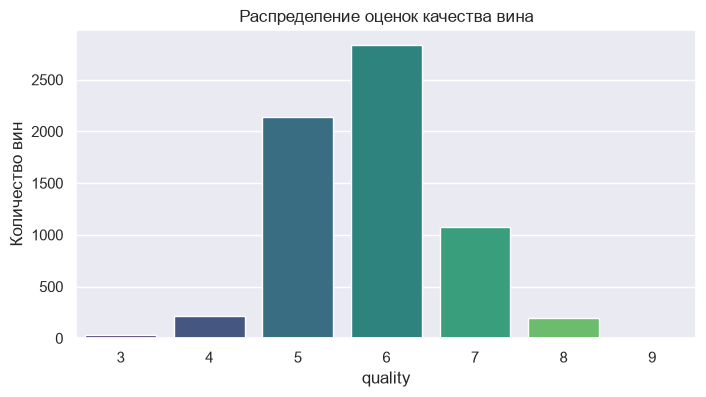

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64


In [5]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='quality', palette='viridis')
plt.title("Распределение оценок качества вина")
plt.xlabel("quality")
plt.ylabel("Количество вин")
plt.show()

print(df['quality'].value_counts().sort_index())

**Вывод:** Вин с оценкой 3, 4, 8, 9 — единицы. Модель будет плохо предсказывает редкие классы, потому что видела их мало.

## Корреляции с целевой переменной

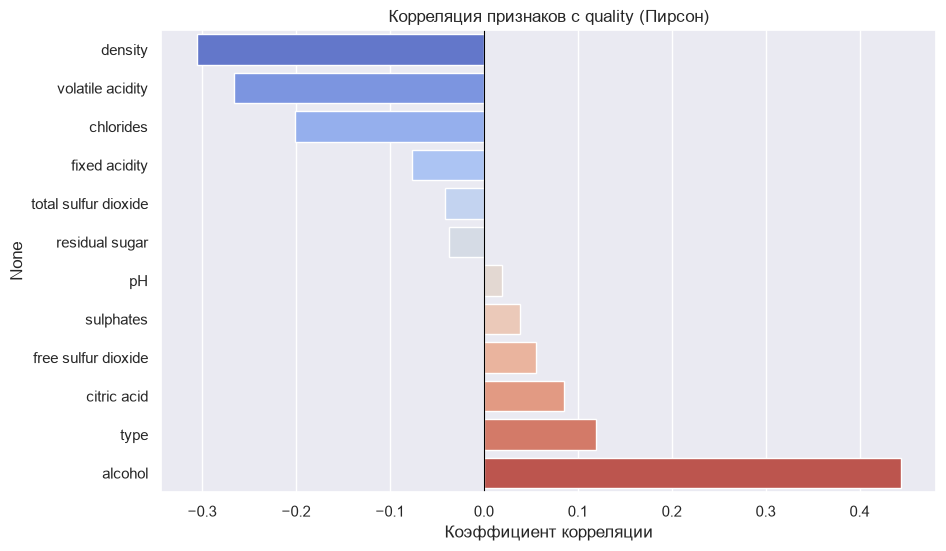

density                -0.305858
volatile acidity       -0.265699
chlorides              -0.200666
fixed acidity          -0.076743
total sulfur dioxide   -0.041385
residual sugar         -0.036980
pH                      0.019506
sulphates               0.038485
free sulfur dioxide     0.055463
citric acid             0.085532
type                    0.119323
alcohol                 0.444319
Name: quality, dtype: float64


In [6]:
plt.figure(figsize=(10, 6))
corr_with_quality = df.corr()['quality'].drop('quality').sort_values() # матрица корреляций Пирсона между всеми парами числовых признаков.
sns.barplot(x=corr_with_quality.values, y=corr_with_quality.index, palette='coolwarm')
plt.title("Корреляция признаков с quality (Пирсон)")
plt.xlabel("Коэффициент корреляции")
plt.axvline(0, color='black', linewidth=0.8)
plt.show()

print(corr_with_quality)

Наибольшая положительная корреляция с quality у признака alcohol (≈0.44): более крепкие вина в среднем получают более высокие оценки. Наибольшая отрицательная — у volatile acidity (≈−0.27): повышенная летучая кислотность ассоциирована с низким качеством. Эти два признака стоит в первую очередь учитывать при моделировании.

## Scatter-plot по топ-признакам

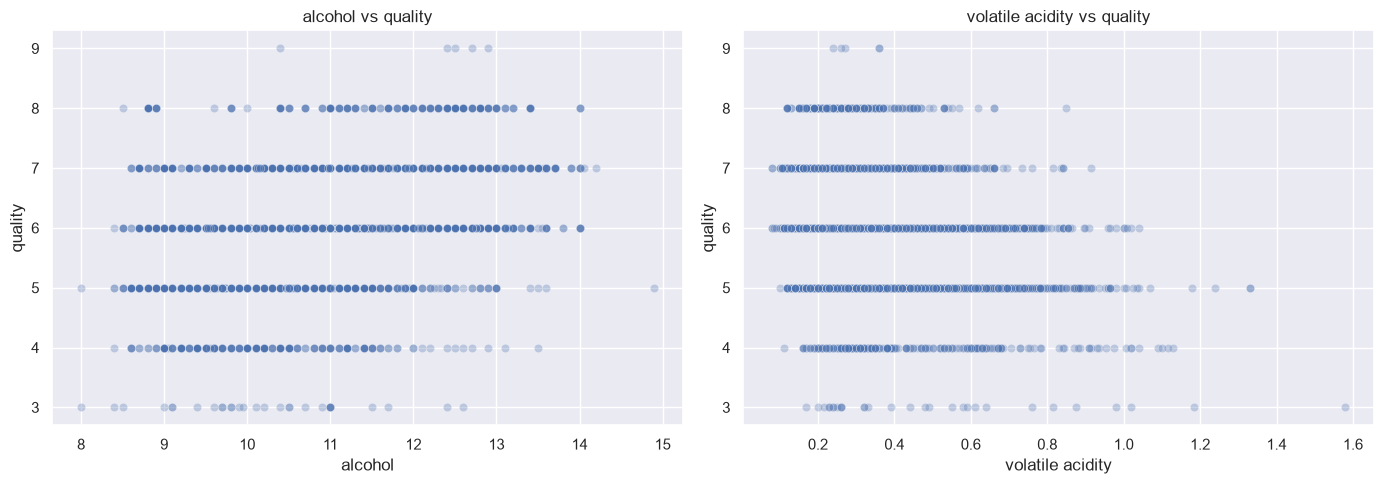

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x='alcohol', y='quality', alpha=0.3, ax=axes[0])
axes[0].set_title("alcohol vs quality")

sns.scatterplot(data=df, x='volatile acidity', y='quality', alpha=0.3, ax=axes[1])
axes[1].set_title("volatile acidity vs quality")

plt.tight_layout()
plt.show()

**Вывод:** Scatter-plot подтверждает корреляции - связь alcohol и quality в целом положительная, но с большим разбросом — значит, одной линейной зависимости недостаточно, и модели, улавливающие нелинейности (деревья), могут дать лучший результат. Обратная картина у volatile acidity: высокие значения почти не встречаются у вин с высокими оценками.

## Разделение на train и test

In [8]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['quality'])
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (5197, 12) Test: (1300, 12)


* X — все признаки (всё, кроме quality), y — целевая переменная.

* train_test_split — делит данные случайно: 80% в train, 20% в test (test_size=0.2).

* random_state=RANDOM_STATE — фиксирует случайность: при повторном запуске разбиение будет тем же. Без этого результаты не воспроизводимы.

Выбрано разбиение 80/20: ~5197 объектов в train достаточно, чтобы модель выучила закономерности, а ~1300 в test — чтобы честно оценить качество. Использовано простое случайное разбиение с фиксированным random_state=42, так как данные не являются временным рядом и не сгруппированы. Тестовая выборка используется только для финальной оценки: если многократно подбирать модель, глядя на тест, произойдёт переобучение на тестовую выборку, и на новых реальных данных качество окажется хуже.

## Baseline

In [9]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

best_constant = y_train.mean() # RMSE минимизируется, когда предсказание равно среднему
print(f"Константа (среднее quality на train): {best_constant:.4f}")

baseline_preds = np.full(shape=y_test.shape, fill_value=best_constant) # создаёт массив предсказаний — одно и то же число для каждого объекта теста

baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_preds)) # читает RMSE baseline
baseline_mae = mean_absolute_error(y_test, baseline_preds) # сравнивает истину с предсказаниями: берёт модуль каждой разности, усредняет

print(f"Baseline RMSE: {baseline_rmse:.4f}")
print(f"Baseline MAE:  {baseline_mae:.4f}")

Константа (среднее quality на train): 5.8145
Baseline RMSE: 0.8596
Baseline MAE:  0.6691


Baseline предсказывает для всех вин одно и то же значение — среднее quality на train (≈5.82). RMSE baseline ≈ 0.86. Это точка отсчёта: если обученная модель не даёт RMSE заметно ниже, она не извлекает из признаков полезной информации. Порог задания (RMSE < 0.70) означает, что модель должна быть существенно лучше константы.

## Ответы на вопросы

* MAE — средняя абсолютная ошибка: на сколько в среднем (в единицах quality) предсказание отличается от истины. Легко интерпретировать.

* RMSE — корень из средней квадратичной ошибки: тоже в единицах quality, но сильнее штрафует крупные промахи.

* Почему RMSE сильнее реагирует на большие ошибки: ошибка возводится в квадрат, поэтому один промах в 3 единицы даёт вклад 9, а промах в 1 — всего 1; большие ошибки доминируют.

* Почему MAE и RMSE могут различаться: если в ошибках есть несколько крупных выбросов, RMSE вырастет значительно сильнее MAE. Большой разрыв между ними — сигнал о наличии крупных ошибок на отдельных объектах.

## Linear Regression

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

lin_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('reg', LinearRegression())
])

lin_pipeline.fit(X_train, y_train)
lin_preds = lin_pipeline.predict(X_test)

lin_rmse = np.sqrt(mean_squared_error(y_test, lin_preds))
lin_mae = mean_absolute_error(y_test, lin_preds)

print(f"Linear Regression RMSE: {lin_rmse:.4f}")
print(f"Linear Regression MAE:  {lin_mae:.4f}")

Linear Regression RMSE: 0.7357
Linear Regression MAE:  0.5644


* Pipeline объединяет шаги: сначала StandardScaler, потом LinearRegression. Главное преимущество: scaler обучается (fit) только на train, а к тесту применяется уже обученное преобразование (transform). 

* StandardScaler — приводит каждый признак к виду (x - среднее) / стандартное отклонение. После этого все признаки в одном масштабе.

Зачем масштабирование: признаки измеряются в разных единицах (кислотность в г/л, алкоголь в %, сульфаты в мг/л). Без масштабирования коэффициенты линейной регрессии несравнимы между собой — признак с большими числами получит маленький коэффициент просто из-за масштаба. После масштабирования коэффициент = изменение quality при изменении признака на одно стандартное отклонение → теперь коэффициенты корректно сравнивать.

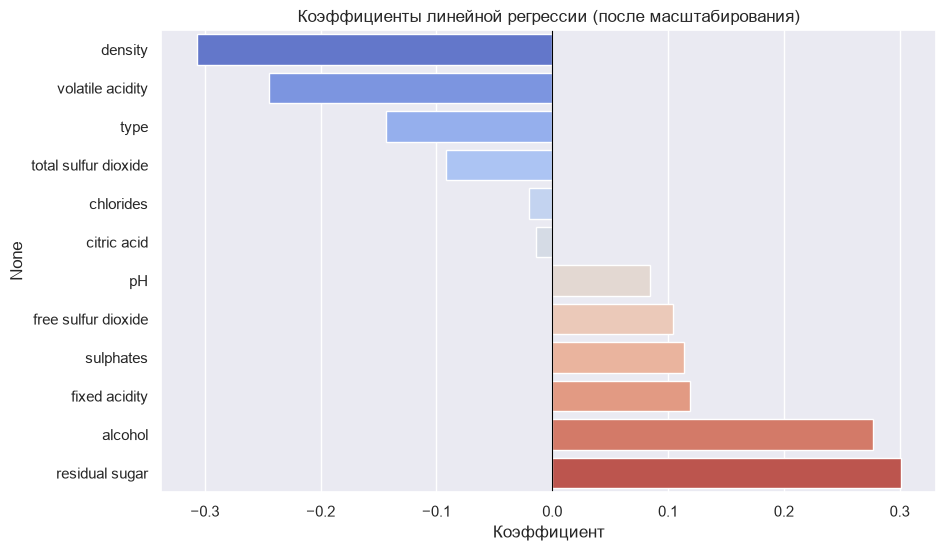

Топ-5 по модулю влияния:
density             0.307099
residual sugar      0.301300
alcohol             0.277079
volatile acidity    0.244675
type                0.143580
dtype: float64


In [11]:
coefs = pd.Series(
    lin_pipeline.named_steps['reg'].coef_,
    index=X.columns
).sort_values()

plt.figure(figsize=(10, 6))
sns.barplot(x=coefs.values, y=coefs.index, palette='coolwarm')
plt.axvline(0, color='black', linewidth=0.8)
plt.title("Коэффициенты линейной регрессии (после масштабирования)")
plt.xlabel("Коэффициент")
plt.show()

print("Топ-5 по модулю влияния:")
print(coefs.abs().sort_values(ascending=False).head())

**Вывод:**
После масштабирования коэффициенты сравнимы: они показывают изменение quality при изменении признака на одно стандартное отклонение. Наибольшее положительное влияние оказывают residual sugar и alcohol, а наибольшее отрицательное влияние оказывают density, volatile acidity и type.

*Более крепкие вина оцениваются **выше**, а высокая летучая кислотность и плотность — **ниже**.*

Однако residual sugar имел слабую парную корреляцию с quality, но оказался одним из сильнейших в многомерной модели. Это объясняется тем, что парная корреляция не учитывает другие признаки, а регрессия оценивает вклад при их контроле. Такое расхождение подчёркивает разницу между корреляцией и многомерным вкладом признака. Отметим, что часть связи density может быть опосредована alcohol и residual sugar, с которыми она сильно коррелирует. Линейная регрессия уловила основные линейные тренды, но её RMSE (~0.74) близок к порогу — значит, часть закономерностей в данных нелинейна.

## Random Forest

In [12]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=100, # 100 деревьев в лесу — стандартный разумный дефолт
    random_state=RANDOM_STATE, # Фиксируем случайность
    n_jobs=-1 # использовать все ядра процессора для параллельного построения деревьев
)

rf.fit(X_train, y_train) # Обучение
rf_preds = rf.predict(X_test) # предсказания

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds)) # вычисление RMSE
rf_mae = mean_absolute_error(y_test, rf_preds) # вычисление MAE

print(f"Random Forest RMSE: {rf_rmse:.4f}")
print(f"Random Forest MAE:  {rf_mae:.4f}")

Random Forest RMSE: 0.6082
Random Forest MAE:  0.4368


### feature importance

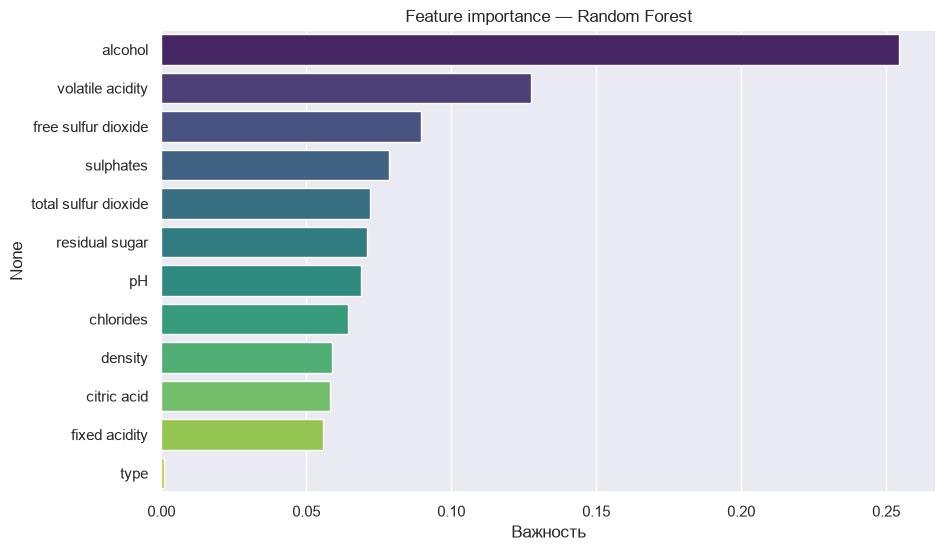

Топ-7 признаков (Random Forest):
alcohol                 0.254585
volatile acidity        0.127507
free sulfur dioxide     0.089717
sulphates               0.078344
total sulfur dioxide    0.071939
residual sugar          0.070934
pH                      0.068788
dtype: float64


In [13]:
rf_importance = pd.Series(           # Массив важностей, по одному числу на признак. 
    index=X.columns                  # Значения неотрицательные, в сумме = 1
    rf.feature_importances_,         # (это доли вклада в уменьшение ошибки при разбиениях).
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=rf_importance.values, y=rf_importance.index, palette='viridis')
plt.title("Feature importance — Random Forest")
plt.xlabel("Важность")
plt.show()

print("Топ-7 признаков (Random Forest):")
print(rf_importance.head(7))

**Вывод:** Random Forest выделил в топе alcohol (25.5%), volatile acidity (12.8%), free sulfur dioxide (9.0%), sulphates (7.8%) и total sulfur dioxide (7.2%). Первые два признака совпадают с топом линейной регрессии и с корреляционным анализом, что подтверждает их ключевую роль.

Однако есть и расхождения: density, лидировавшая в линейной модели, в лесу не попала в топ-7 — вероятно, потому что лес использует напрямую alcohol и residual sugar, а density для него избыточна (её связь опосредована составом вина). Наоборот, признаки содержания серы (free и total sulfur dioxide) и sulphates поднялись в лесу выше, чем в линейной модели: деревья способны улавливать нелинейные и немонотонные зависимости, которые линейная регрессия не выражает. Таким образом, важность признака зависит от модели: она показывает, насколько признак полезен для предсказания в рамках конкретного алгоритма.

## Gradient Boosting

In [14]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1, # «Шаг» обучения. Каждое дерево добавляется с весом 0.1
    max_depth=3, # глубина каждого дерева.
    random_state=RANDOM_STATE
)

gb.fit(X_train, y_train) # Обучение модели
gb_preds = gb.predict(X_test) # Строит массив предсказаний

gb_rmse = np.sqrt(mean_squared_error(y_test, gb_preds))
gb_mae = mean_absolute_error(y_test, gb_preds) 

print(f"Gradient Boosting RMSE: {gb_rmse:.4f}")
print(f"Gradient Boosting MAE:  {gb_mae:.4f}")

Gradient Boosting RMSE: 0.6784
Gradient Boosting MAE:  0.5322


### feature importance

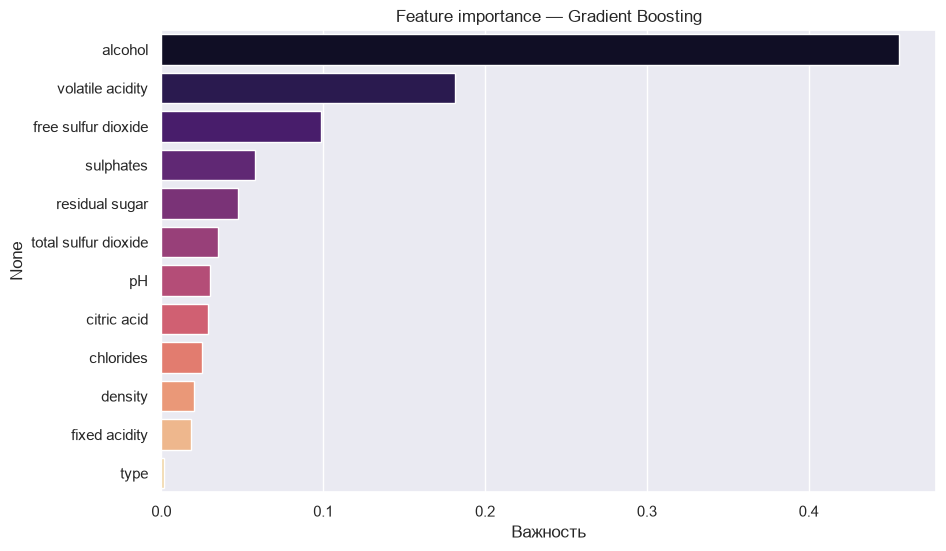

Топ-7 признаков (Gradient Boosting):
alcohol                 0.456073
volatile acidity        0.181419
free sulfur dioxide     0.098402
sulphates               0.057764
residual sugar          0.047441
total sulfur dioxide    0.035221
pH                      0.030099
dtype: float64


In [15]:
gb_importance = pd.Series(
    gb.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=gb_importance.values, y=gb_importance.index, palette='magma')
plt.title("Feature importance — Gradient Boosting")
plt.xlabel("Важность")
plt.show()

print("Топ-7 признаков (Gradient Boosting):")
print(gb_importance.head(7))

**Вывод:** Gradient Boosting выделил в топе alcohol (45.6%), volatile acidity (18.1%), free sulfur dioxide (9.8%), sulphates (5.8%) и residual sugar (4.7%). По сравнению с Random Forest бустинг сконцентрировал важность на alcohol (45.6% против 25.5%): последовательное построение деревьев заставляет модель сильнее опираться на доминирующий признак, тогда как независимые деревья леса распределяют важность равномернее. Несмотря на это, топ-2 признака (alcohol и volatile acidity) совпадают у обеих моделей и с результатами EDA и линейной регрессии — три независимых метода указывают на одни и те же ключевые сигналы. 

Примечательно, что density, лидировавшая в линейной модели, не попала в топ у обеих древовидных моделей: это подтверждает гипотезу о том, что её связь с quality опосредована alcohol и residual sugar, а деревья используют посредников напрямую. Feature importance отражает полезность признака для предсказания в конкретной модели, но не направление влияния и не причинно-следственную связь.

## Итоговая таблица

In [16]:
results = pd.DataFrame({
    'Модель': ['Baseline', 'Linear Regression', 'Random Forest', 'Gradient Boosting'],
    'RMSE': [baseline_rmse, lin_rmse, rf_rmse, gb_rmse],
    'MAE':  [baseline_mae,  lin_mae,  rf_mae,  gb_mae]
}).sort_values('RMSE')

results

,Модель,RMSE,MAE
2,Random Forest,0.608227,0.436754
3,Gradient Boosting,0.678413,0.532242
1,Linear Regression,0.735689,0.564413
0,Baseline,0.859605,0.669097


**Общий вывод:** Все модели превзошли baseline (RMSE 0.86), что подтверждает: признаки несут полезную информацию. Победитель — Random Forest (RMSE 0.608, MAE 0.437), единственная модель с уверенным запасом ниже порога 0.70. Gradient Boosting (0.678) — второй и едва проходит порог, Linear Regression (0.736) порог не проходит.

Неожиданно лес обошёл бустинг, хотя обычно бустинг точнее. Причины: (1) гиперпараметры не подбирались — использованы дефолтные настройки, а бустинг к ним чувствителен, тогда как лес с 100 деревьями стабилен; (2) неглубокие деревья бустинга (max_depth=3) могли недообучиться; (3) в данных есть выбросы (residual sugar до 65.8, sulfur до 440), а бустинг последовательно фокусируется на ошибках и может переобучаться на выбросах, тогда как усреднение независимых деревьев леса гасит их влияние; (4) бустинг сконцентрировал 45.6% важности на alcohol, что делает его менее гибким.

Линейная регрессия уступает деревьям, потому что ищет только линейные зависимости и не улавливает нелинейности и взаимодействия (например, немонотонное влияние серы), которые деревья выражают через разбиения. Показательно, что density, лидировавшая в линейной модели, деревьями проигнорирована, а точность при этом выше — подтверждение того, что density была косвенным индикатором, а не прямым драйвером.

У всех моделей RMSE заметно превышает MAE (например, RF: 0.608 vs 0.437), что указывает на наличие отдельных крупных ошибок — выбросов, которые RMSE штрафует сильнее. Это мотивирует отдельный анализ ошибок.

## Анализ ошибок

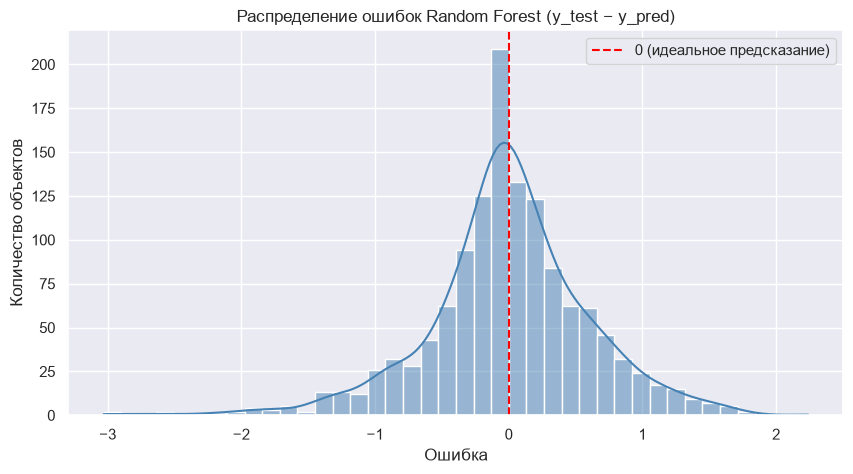

Среднее ошибок: -0.0007
Стандартное отклонение ошибок: 0.6085
Минимальная ошибка: -3.0300
Максимальная ошибка: 2.2400


In [17]:
# Ошибки на тесте: истина минус предсказание
rf_errors = y_test - rf_preds

plt.figure(figsize=(10, 5))
sns.histplot(rf_errors, bins=40, kde=True, color='steelblue')
plt.axvline(0, color='red', linestyle='--', label='0 (идеальное предсказание)')
plt.title("Распределение ошибок Random Forest (y_test − y_pred)")
plt.xlabel("Ошибка")
plt.ylabel("Количество объектов")
plt.legend()
plt.show()

print(f"Среднее ошибок: {rf_errors.mean():.4f}")
print(f"Стандартное отклонение ошибок: {rf_errors.std():.4f}")
print(f"Минимальная ошибка: {rf_errors.min():.4f}")
print(f"Максимальная ошибка: {rf_errors.max():.4f}")

**Вывод:** Распределение ошибок Random Forest симметрично относительно нуля: средняя ошибка ≈ −0.0007, то есть модель не имеет систематического смещения — она не завышает и не занижает оценки в среднем. Основная масса ошибок лежит в диапазоне от −1 до +1 (большинство объектов предсказаны с точностью лучше одного балла). Однако присутствуют тяжёлые хвосты: минимальная ошибка −3.03, максимальная +2.24; левый хвост длиннее, что означает, что среди крупных промахов преобладает переоценка (модель предсказала больше, чем истинное значение). Именно эти единичные крупные ошибки объясняют, почему RMSE (0.608) заметно превышает MAE (0.437): RMSE возводит ошибки в квадрат и потому сильнее реагирует на выбросы. Стандартное отклонение ошибок (0.609) близко к RMSE, что ожидаемо при среднем, близком к нулю.

In [18]:
error_df = pd.DataFrame({
    'true': y_test,
    'pred': rf_preds,
    'error': rf_errors,
    'abs_error': np.abs(rf_errors)
}).sort_values('abs_error', ascending=False)

print("Топ-10 объектов с наибольшей абсолютной ошибкой:")
print(error_df.head(10))

# Посмотрим на их признаки
worst_idx = error_df.head(5).index
print("\nПризнаки объектов с наибольшими ошибками:")
print(X_test.loc[worst_idx].T)

Топ-10 объектов с наибольшей абсолютной ошибкой:
      true  pred  error  abs_error
2339     3  6.03  -3.03       3.03
6344     3  5.91  -2.91       2.91
3649     3  5.63  -2.63       2.63
3016     3  5.55  -2.55       2.55
3715     4  6.26  -2.26       2.26
3204     9  6.76   2.24       2.24
1374     3  5.22  -2.22       2.22
4656     5  7.10  -2.10       2.10
3758     4  6.00  -2.00       2.00
1235     4  5.96  -1.96       1.96

Признаки объектов с наибольшими ошибками:
                         2339       6344      3649      3016     3715
fixed acidity          6.9000    6.10000   11.8000    8.6000   6.8000
volatile acidity       0.3900    0.26000    0.2300    0.5500   0.2000
citric acid            0.4000    0.25000    0.3800    0.3500   0.2700
residual sugar         4.6000    2.90000   11.1000   15.5500   1.2000
chlorides              0.0220    0.04700    0.0340    0.0570   0.0340
free sulfur dioxide    5.0000  289.00000   15.0000   35.5000  19.0000
total sulfur dioxide  19.0000  44

Топ-10 объектов с наибольшими ошибками показывает чёткую закономерность: 8 из 10 — это вина с истинной оценкой 3 или 4, ещё одно — с оценкой 9. То есть крупные промахи сосредоточены на редких классах, что напрямую связано с дисбалансом, выявленным в EDA. Модель «притягивает» крайние значения к центру распределения: для истинного 3 она предсказывает около 5.5–6, для истинного 9 — около 6.8. Это классическая регрессия к среднему: модель не уверена в экстремальных оценках и предсказывает ближе к типичным значениям.

Причины отдельных промахов подтверждаются признаками объектов. Объект 6344 имеет экстремальные значения free sulfur dioxide (289) и total sulfur dioxide (440) — это максимумы по датасету (выбросы), которые почти не встречались в обучении. Объект 2339 сочетает очень высокий алкоголь (12.6) с крайне низким содержанием серы (5 и 19) — необычная комбинация, которая «обманула» модель: по отдельности сигналы выглядят «хорошо», но эксперты оценили вино на 3. Объекты 3649 и 3016 имеют высокий остаточный сахар и высокую серу — редкие комбинации.

**Вывод:** хорошее среднее значение RMSE не означает, что модель одинаково хороша на всех объектах. Крупные ошибки приходятся на редкие классы и выбросы, слабо представленные в обучении. Это объясняет, почему RMSE (0.608) заметно превышает MAE (0.437): единичные промахи на аномалиях сильно влияют на квадратичную метрику.

           MAE  count
true                 
3     2.525000      6
4     1.194186     43
5     0.390721    402
6     0.324338    597
7     0.509256    215
8     1.079167     36
9     2.240000      1


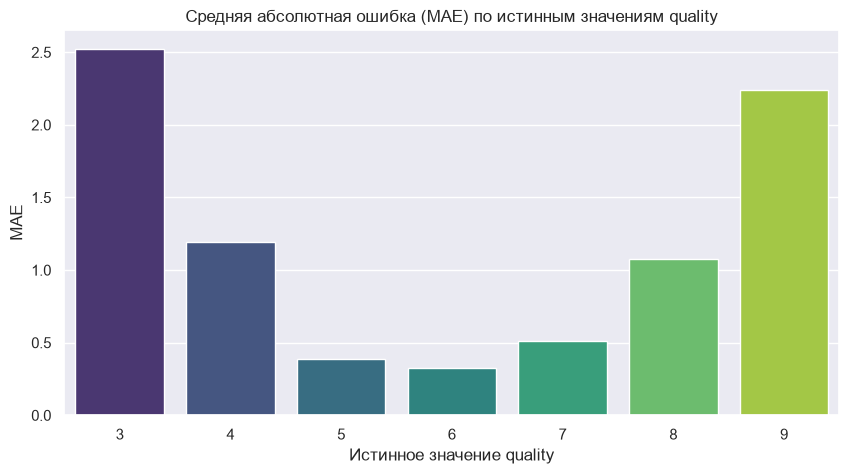


Количество объектов каждого класса в тесте:
quality
3      6
4     43
5    402
6    597
7    215
8     36
9      1
Name: count, dtype: int64


In [19]:
# Средняя абсолютная ошибка для каждого истинного значения quality
mae_by_quality = error_df.groupby('true')['abs_error'].agg(['mean', 'count'])
mae_by_quality.columns = ['MAE', 'count']
print(mae_by_quality)

# Визуализация
plt.figure(figsize=(10, 5))
sns.barplot(x=mae_by_quality.index, y=mae_by_quality['MAE'], palette='viridis')
plt.title("Средняя абсолютная ошибка (MAE) по истинным значениям quality")
plt.xlabel("Истинное значение quality")
plt.ylabel("MAE")
plt.show()

# Распределение истинных значений в тесте (сколько объектов каждого класса)
print("\nКоличество объектов каждого класса в тесте:")
print(y_test.value_counts().sort_index())

**Вывод:** Модель работает крайне неравномерно по разным значениям quality, что видно по U-образной зависимости MAE от класса. Для центральных, часто встречающихся оценок (5, 6, 7) MAE мала (0.32–0.51), тогда как для редких крайних классов (3, 4, 8, 9) она резко возрастает (1.08–2.53). При этом прослеживается прямая связь с количеством объектов: чем больше примеров класса в данных (6 → 597 объектов), тем ниже ошибка (0.324), и наоборот (9 → 1 объект, MAE 2.24).

Это прямое следствие дисбаланса классов, выявленного в EDA: модель учится преимущественно на частых оценках 5–7 и почти не видела редких 3, 4, 8, 9. Кроме того, наблюдается регрессия к среднему — для крайних истинных значений модель предсказывает оценки ближе к центру распределения. Класс 9 представлен одним объектом, поэтому его MAE статистически ненадёжен, но общая тенденция подтверждается классами 3, 4 и 8.

Эта неравномерность объясняет разрыв между RMSE (0.608) и MAE (0.437): сотни объектов с малой ошибкой тянут MAE вниз, но несколько объектов с ошибкой 2–3 балла сильно увеличивают RMSE из-за возведения в квадрат. Таким образом, хорошее среднее значение метрики скрывает плохую работу модели на редких классах.

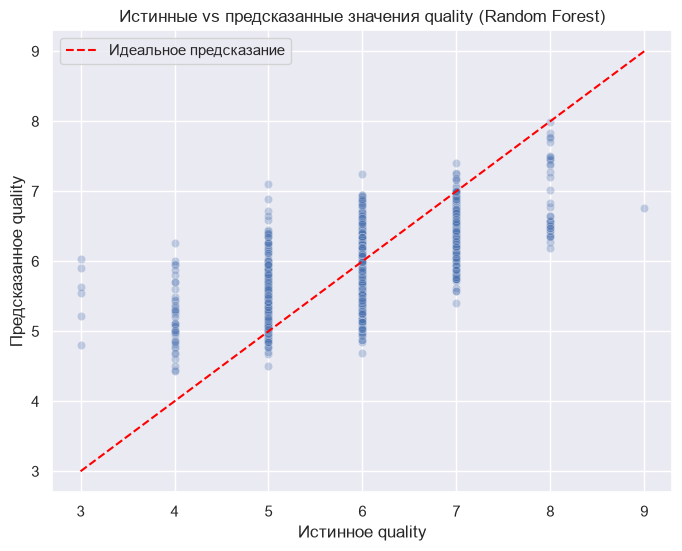

In [20]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=rf_preds, alpha=0.3)
plt.plot([3, 9], [3, 9], color='red', linestyle='--', label='Идеальное предсказание')
plt.title("Истинные vs предсказанные значения quality (Random Forest)")
plt.xlabel("Истинное quality")
plt.ylabel("Предсказанное quality")
plt.legend()
plt.show()

Scatter-plot истинных и предсказанных значений наглядно подтверждает неравномерность работы модели. Для центральных, часто встречающихся оценок (5, 6, 7) точки плотно группируются вдоль линии идеального предсказания — модель точна. Для редких крайних значений (3, 4, 8, 9) точки сильно отклоняются от линии: истинные 3 и 4 модель завышает (предсказывает 4.5–6), а истинные 8 и 9 занижает (6.2–7.6).

Особенно заметно «сжатие» облака предсказаний по вертикали: модель почти никогда не предсказывает крайние значения 3 и 9, все её предсказания сосредоточены в диапазоне примерно 4.5–7.5, хотя истинные значения охватывают 3–9. Это визуальное проявление регрессии к среднему: модель не уверена в экстремальных оценках и «осторожно» предсказывает ближе к центру распределения. График согласуется с таблицей MAE по классам и разбором крупных ошибок: все три анализа указывают на одну и ту же закономерность — модель хорошо работает на частых классах и плохо на редких.